# Obesity Risk Analytics Pipeline



## Step 0: Setup (install packages, place the dataset, set working directory)

In [17]:
# Install the required packages (takes a few minutes the first time)
install.packages(c("glmnet", "randomForest", "e1071"))

# Put the uploaded dataset into the project's data folder and move there
dir.create("/content/Obesity_Risk_Analytics/data", recursive = TRUE)
file.copy("/content/obesity_level.csv", "/content/Obesity_Risk_Analytics/data/obesity_level.csv")
setwd("/content/Obesity_Risk_Analytics")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message in dir.create("/content/Obesity_Risk_Analytics/data", recursive = TRUE):
“'/content/Obesity_Risk_Analytics/data' already exists”


[1] FALSE

In [18]:
# Helper used only for showing saved files inside the notebook (not part of the original scripts)
show_plots <- function(files) {
  for (f in files) {
    cat("\n>>", f, "\n")
    IRdisplay::display_png(file = f)
  }
}
show_text <- function(f) {
  cat("\n----- Saved output file:", f, "-----\n")
  cat(readLines(f), sep = "\n")
}

## Step 1: Setup and Data Cleaning (`01_setup_and_cleaning.R`)

In [19]:
# =============================================================================
# 01: SETUP AND DATA CLEANING
# =============================================================================

# 1: Load data and Rename Target
# Read the CSV file and rename the last column to the correct target name
data <- read.csv("data/obesity_level.csv", stringsAsFactors = FALSE)
names(data)[ncol(data)] <- "Obesity_Level"


# 2: Remove ID and Duplicates
# Remove the ID column because it is not useful for analysis
data$id <- NULL

# Remove duplicate rows to avoid using the same record more than once
data <- unique(data)


# 3: Fix Corrupted Category Labels
# Correct the typo in the target variable
data$Obesity_Level <- ifelse(
  data$Obesity_Level == "0rmal_Weight",
  "Normal_Weight",
  data$Obesity_Level
)

# Replace incorrect "0" values with "no" in categorical variables
data$CAEC <- ifelse(data$CAEC == "0", "no", data$CAEC)
data$CALC <- ifelse(data$CALC == "0", "no", data$CALC)


# 4: Check for Missing Values
# Count the missing values in each column
missing_values <- colSums(is.na(data))

cat("\n===== Missing Value Check =====\n")

# Display the result clearly
if (sum(missing_values) == 0) {
  cat("No missing values were found in the dataset.\n")
} else {
  cat("Missing values found in the following columns:\n")
  print(missing_values[missing_values > 0])
}


# 5: Logical Correction of Synthetic Variables
# Round survey variables to whole numbers where appropriate
survey_vars <- c("FCVC", "NCP", "CH2O", "FAF", "TUE")

for (var in survey_vars) {
  data[[var]] <- round(data[[var]])
}


# 6: Feature Engineering
# Calculate BMI and add it as a new column
data$BMI <- data$Weight / (data$Height^2)

# Create age groups for descriptive analysis and dashboards
data$Age_Group <- cut(
  data$Age,
  breaks = c(0, 19, 35, 55, 100),
  labels = c("Teen", "Young_Adult", "Adult", "Senior"),
  right = FALSE
)

# Convert the seven obesity levels into two groups:
# Obese and Not_Obese
data$Obese_Binary <- ifelse(
  data$Obesity_Level %in% c(
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III"
  ),
  "Obese",
  "Not_Obese"
)


# 7: Handle Age Outliers Without Data Leakage
# Create a stratified 80% training set by sampling from each obesity level
set.seed(2026)

train_idx <- unname(unlist(
  tapply(
    1:nrow(data),
    data$Obesity_Level,
    function(x) {
      sample(x, size = round(0.8 * length(x)))
    }
  )
))

# Calculate the 99th percentile of Age using only the training data
upper_age_bound <- quantile(data$Age[train_idx], 0.99)

# Cap Age values above the training-based upper limit
data$Age <- ifelse(
  data$Age > upper_age_bound,
  upper_age_bound,
  data$Age
)


# 8: Convert Binary and Categorical Variables to Factors

# Convert binary variables from 0/1 into No/Yes
binary_vars <- c(
  "family_history_with_overweight",
  "FAVC",
  "SMOKE",
  "SCC"
)

for (var in binary_vars) {
  data[[var]] <- factor(
    data[[var]],
    levels = c(0, 1),
    labels = c("No", "Yes")
  )
}

# Convert other categorical variables into factors
data$Gender <- factor(data$Gender)
data$MTRANS <- factor(data$MTRANS)
data$Obese_Binary <- factor(data$Obese_Binary)

# Set the order of the CAEC categories
data$CAEC <- factor(
  data$CAEC,
  levels = c("no", "Sometimes", "Frequently", "Always")
)

# Set the order of the CALC categories
data$CALC <- factor(
  data$CALC,
  levels = c("no", "Sometimes", "Frequently", "Always")
)

# Set the obesity levels from lower to higher weight categories
data$Obesity_Level <- factor(
  data$Obesity_Level,
  levels = c(
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III"
  )
)


# 9: Save Cleaned Data
# Save the cleaned dataset as CSV and RDS files
write.csv(
  data,
  "data/obesity_clean.csv",
  row.names = FALSE
)

saveRDS(
  data,
  "data/obesity_clean.rds"
)

cat("\nCleaned dataset saved successfully.\n")


===== Missing Value Check =====
No missing values were found in the dataset.

Cleaned dataset saved successfully.


## Step 2: Descriptive Analysis (`02_descriptive_analysis.R`)

Data loaded successfully. Creating plots...


agg_record_7877031600c 
                     2

Plot 1 generated: Target Distribution.

===== Binary Obesity Class Distribution =====
   Category Count Percentage
1 Not_Obese 10554      50.84
2     Obese 10204      49.16


png 
  3

agg_record_7877031600c 
                     2

...

agg_record_7877031600c 
                     2

agg_record_7877031600c 
                     2

Plots 7, 8 & 9 generated: Advanced Business Insights.


agg_record_7877031600c 
                     2

Plot 6 generated: Correlation Matrix.
Weight and BMI show high multicollinearity. Avoid using both together in linear regression.
Descriptive statistics table saved successfully.


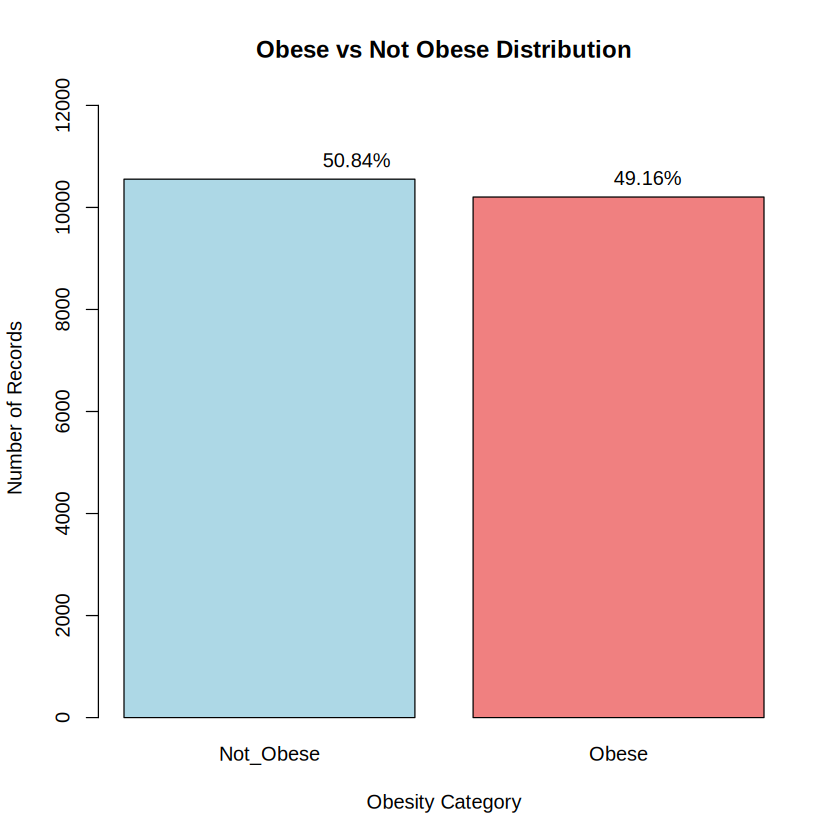

In [20]:
# =============================================================================
# 02: ADVANCED DESCRIPTIVE ANALYSIS
# =============================================================================

# 1: Setup and Directory Creation
# Create output folders automatically so the script works on a new PC
dir.create("outputs/plots", recursive = TRUE, showWarnings = FALSE)

# Load the cleaned dataset
data <- readRDS("data/obesity_clean.rds")

cat("Data loaded successfully. Creating plots...\n")


# =============================================================================
# 2: Target Variable Distribution
# =============================================================================

# Show the distribution of the seven original obesity levels
png(
  "outputs/plots/01_target_distribution.png",
  width = 800,
  height = 600
)

# Increase the bottom margin so the long class names are not cut off
par(mar = c(11, 4, 4, 2) + 0.1)

counts <- table(data$Obesity_Level)
percentages <- round(prop.table(counts) * 100, 1)

# Add percentages to the class names
labels_with_pct <- paste0(
  names(counts),
  "\n(",
  percentages,
  "%)"
)

barplot(
  counts,
  main = "Distribution of Obesity Level (Target Variable)",
  col = "steelblue",
  las = 2,
  cex.names = 0.8,
  names.arg = labels_with_pct
)

# Reset the plot margins
par(mar = c(5, 4, 4, 2) + 0.1)

dev.off()

cat("Plot 1 generated: Target Distribution.\n")

# =============================================================================
# 2.1: Binary Obesity Class Distribution
# =============================================================================

# Count the number of Obese and Not Obese records
binary_counts <- table(data$Obese_Binary)

# Calculate the percentage of each group
binary_percentages <- round(
  prop.table(binary_counts) * 100,
  2
)

# Create a table with counts and percentages
binary_distribution <- data.frame(
  Category = names(binary_counts),
  Count = as.vector(binary_counts),
  Percentage = as.vector(binary_percentages)
)

# Display the binary class distribution in the console
cat("\n===== Binary Obesity Class Distribution =====\n")
print(binary_distribution)

# Save the distribution table for the report
write.csv(
  binary_distribution,
  "outputs/binary_obesity_distribution.csv",
  row.names = FALSE
)


# Create the binary obesity distribution plot
# The plot is displayed in RStudio and also saved as a PNG file
barplot(
  binary_counts,
  main = "Obese vs Not Obese Distribution",
  xlab = "Obesity Category",
  ylab = "Number of Records",
  col = c("lightblue", "lightcoral"),
  ylim = c(0, max(binary_counts) * 1.15)
)

# Add the percentage above each bar
text(
  x = seq_along(binary_counts),
  y = binary_counts,
  labels = paste0(binary_percentages, "%"),
  pos = 3
)

# Save the current plot as a PNG file
dev.copy(
  png,
  filename = "outputs/plots/01_binary_obesity_distribution.png",
  width = 800,
  height = 600
)

dev.off()

cat("Binary obesity distribution plot generated successfully.\n")


# =============================================================================
# 3: Histograms of Numeric Variables
# =============================================================================

# Analyze the shape and spread of continuous variables
num_vars <- c(
  "Age",
  "Height",
  "Weight",
  "BMI",
  "FCVC",
  "NCP",
  "CH2O",
  "FAF",
  "TUE"
)

png(
  "outputs/plots/02_numeric_histograms.png",
  width = 1000,
  height = 800
)

# Set up a 3x3 grid for the nine numeric variables
par(mfrow = c(3, 3))

for (v in num_vars) {
  hist(
    data[[v]],
    main = paste("Distribution of", v),
    xlab = v,
    col = "lightblue",
    border = "white",
    breaks = 20
  )
}

# Reset the plotting layout
dev.off()
par(mfrow = c(1, 1))

cat("Plot 2 generated: Numeric Histograms.\n")


# =============================================================================
# 4: Validating Data through Boxplots
# =============================================================================

# Check whether BMI aligns with the obesity level categories
png(
  "outputs/plots/03_boxplot_bmi_by_class.png",
  width = 900,
  height = 600
)

# Increase the bottom margin for the long class names
par(mar = c(12, 4, 4, 2) + 0.1)

boxplot(
  BMI ~ Obesity_Level,
  data = data,
  col = "lightgreen",
  main = "BMI Validation by Obesity Level",
  xlab = "",
  ylab = "BMI",
  las = 2,
  cex.axis = 0.8
)

# Reset the margins
par(mar = c(5, 4, 4, 2) + 0.1)

dev.off()


# Print outlier summary to the console
cat("\nOutliers Summary (1.5 * IQR rule):\n")

for (v in c("Weight", "BMI")) {

  q <- quantile(data[[v]], c(0.25, 0.75))
  iqr <- IQR(data[[v]])

  n_out <- sum(
    data[[v]] < (q[1] - 1.5 * iqr) |
      data[[v]] > (q[2] + 1.5 * iqr)
  )

  cat(
    "  ->",
    v,
    "Extreme Values:",
    n_out,
    "(Kept as they represent Obesity Type III)\n"
  )
}


# =============================================================================
# 5: Business Insight Visualizations
# =============================================================================

# Compare Age Group against obesity rates
png(
  "outputs/plots/04_obesity_by_age_group.png",
  width = 700,
  height = 500
)

tbl_age <- table(
  data$Obese_Binary,
  data$Age_Group
)

barplot(
  prop.table(tbl_age, margin = 2),
  main = "Obesity Rate by Age Group",
  col = c("lightgray", "salmon"),
  xlab = "Age Group",
  ylab = "Proportion",
  xlim = c(0, 6)
)

legend(
  "topright",
  legend = rownames(tbl_age),
  fill = c("lightgray", "salmon"),
  bty = "n"
)

dev.off()


# Compare Family History against obesity rates
png(
  "outputs/plots/05_obesity_by_family_history.png",
  width = 700,
  height = 500
)

tbl_fam <- table(
  data$Obese_Binary,
  data$family_history_with_overweight
)

barplot(
  prop.table(tbl_fam, margin = 2),
  main = "Obesity Risk based on Family History",
  col = c("lightgray", "salmon"),
  xlab = "Family History of Overweight",
  xlim = c(0, 4)
)

legend(
  "topright",
  legend = rownames(tbl_fam),
  fill = c("lightgray", "salmon"),
  bty = "n"
)

dev.off()

cat("\nPlots 4 & 5 generated: Business Insights (Age Group & Family History).\n")


# =============================================================================
# 5.1: Advanced Business Insights
# =============================================================================

cat("[INFO] Generating additional strategic business plots...\n")


# Plot 7: Impact of Snacking on BMI
png(
  "outputs/plots/07_bmi_by_snacking_caec.png",
  width = 800,
  height = 500
)

boxplot(
  BMI ~ CAEC,
  data = data,
  col = c("white", "lightyellow", "orange", "red"),
  main = "Impact of Snacking (Eating Between Meals) on BMI",
  xlab = "Frequency of Snacking (CAEC)",
  ylab = "BMI",
  cex.axis = 1.2
)

dev.off()


# Plot 8: Calorie Monitoring vs Obesity Rate
png(
  "outputs/plots/08_obesity_by_calorie_monitoring.png",
  width = 700,
  height = 500
)

tbl_scc <- table(
  data$Obese_Binary,
  data$SCC
)

barplot(
  prop.table(tbl_scc, margin = 2),
  main = "Obesity Risk by Calorie Monitoring (SCC)",
  col = c("lightgray", "salmon"),
  xlab = "Monitors Calories?",
  ylab = "Proportion",
  xlim = c(0, 4)
)

legend(
  "topright",
  legend = rownames(tbl_scc),
  fill = c("lightgray", "salmon"),
  bty = "n"
)

dev.off()


# Plot 9: Obesity Level Distribution by Gender
png(
  "outputs/plots/09_obesity_by_gender.png",
  width = 900,
  height = 600
)

# Increase the bottom margin for long class names
par(mar = c(12, 4, 4, 2) + 0.1)

tbl_gender <- table(
  data$Gender,
  data$Obesity_Level
)

barplot(
  prop.table(tbl_gender, margin = 2),
  main = "Gender Distribution Across Obesity Levels",
  col = c("pink", "lightblue"),
  las = 2,
  ylab = "Proportion",
  xlim = c(0, 10)
)

legend(
  "topright",
  legend = rownames(tbl_gender),
  fill = c("pink", "lightblue"),
  bty = "n",
  title = "Gender"
)

# Reset the margins
par(mar = c(5, 4, 4, 2) + 0.1)

dev.off()

cat("Plots 7, 8 & 9 generated: Advanced Business Insights.\n")


# =============================================================================
# 6: Correlation Matrix
# =============================================================================

# Identify highly correlated numeric variables
cor_matrix <- cor(data[, num_vars])

png(
  "outputs/plots/06_correlation_matrix.png",
  width = 800,
  height = 800
)

# Draw the correlation heatmap
image(
  1:ncol(cor_matrix),
  1:ncol(cor_matrix),
  cor_matrix,
  axes = FALSE,
  xlab = "",
  ylab = "",
  main = "Correlation Matrix (Values > 0.7 indicate high multicollinearity)",
  col = colorRampPalette(c("blue", "white", "red"))(50),
  zlim = c(-1, 1)
)

# Add axis labels
axis(
  1,
  at = 1:ncol(cor_matrix),
  labels = colnames(cor_matrix),
  las = 2,
  cex.axis = 1.1
)

axis(
  2,
  at = 1:ncol(cor_matrix),
  labels = colnames(cor_matrix),
  las = 2,
  cex.axis = 1.1
)

# Add the correlation values inside the boxes
for (x in 1:ncol(cor_matrix)) {
  for (y in 1:ncol(cor_matrix)) {

    val <- round(cor_matrix[x, y], 2)

    # Use white text when the background is dark
    text_color <- ifelse(
      abs(val) > 0.6,
      "white",
      "black"
    )

    text(
      x,
      y,
      labels = val,
      col = text_color,
      cex = 1.2,
      font = 2
    )
  }
}

dev.off()

cat("Plot 6 generated: Correlation Matrix.\n")
cat("Weight and BMI show high multicollinearity. Avoid using both together in linear regression.\n")


# =============================================================================
# 7: Descriptive Statistics Summary Table
# =============================================================================

# Create a summary table for the numeric variables
desc_table <- data.frame(
  Variable = num_vars,
  Mean = round(
    sapply(num_vars, function(v) mean(data[[v]])),
    2
  ),
  Median = round(
    sapply(num_vars, function(v) median(data[[v]])),
    2
  ),
  SD = round(
    sapply(num_vars, function(v) sd(data[[v]])),
    2
  ),
  Min = round(
    sapply(num_vars, function(v) min(data[[v]])),
    2
  ),
  Max = round(
    sapply(num_vars, function(v) max(data[[v]])),
    2
  )
)

# Save the descriptive statistics for the final report
write.csv(
  desc_table,
  "outputs/descriptive_statistics_table.csv",
  row.names = FALSE
)

cat("Descriptive statistics table saved successfully.\n")

### Step 2 plots (saved by the script as PNG files, shown here)

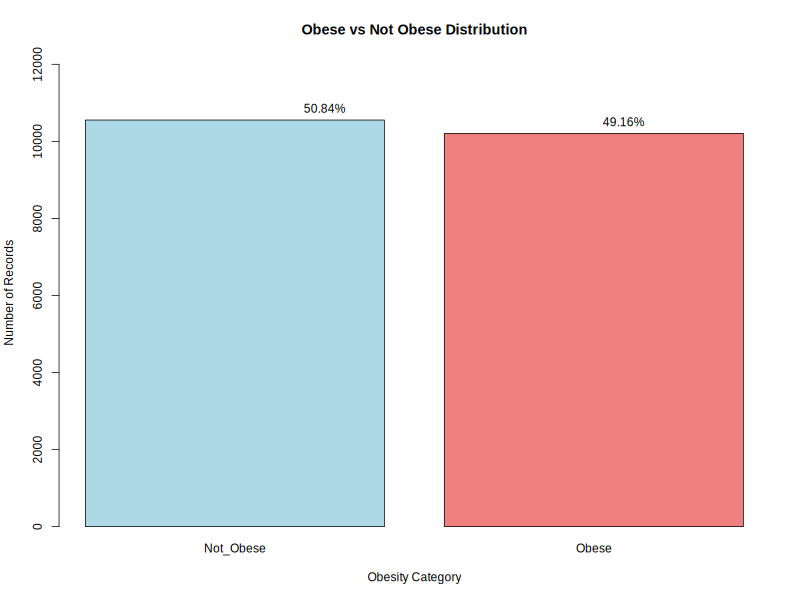

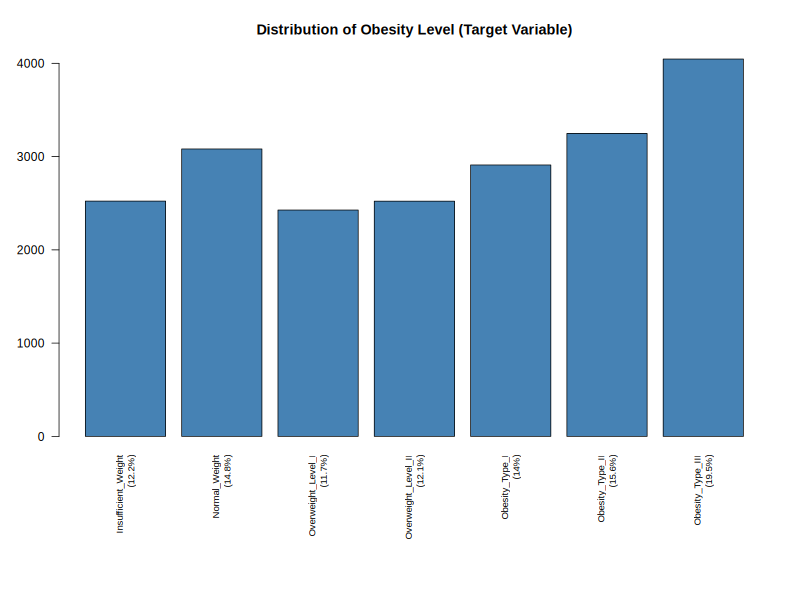

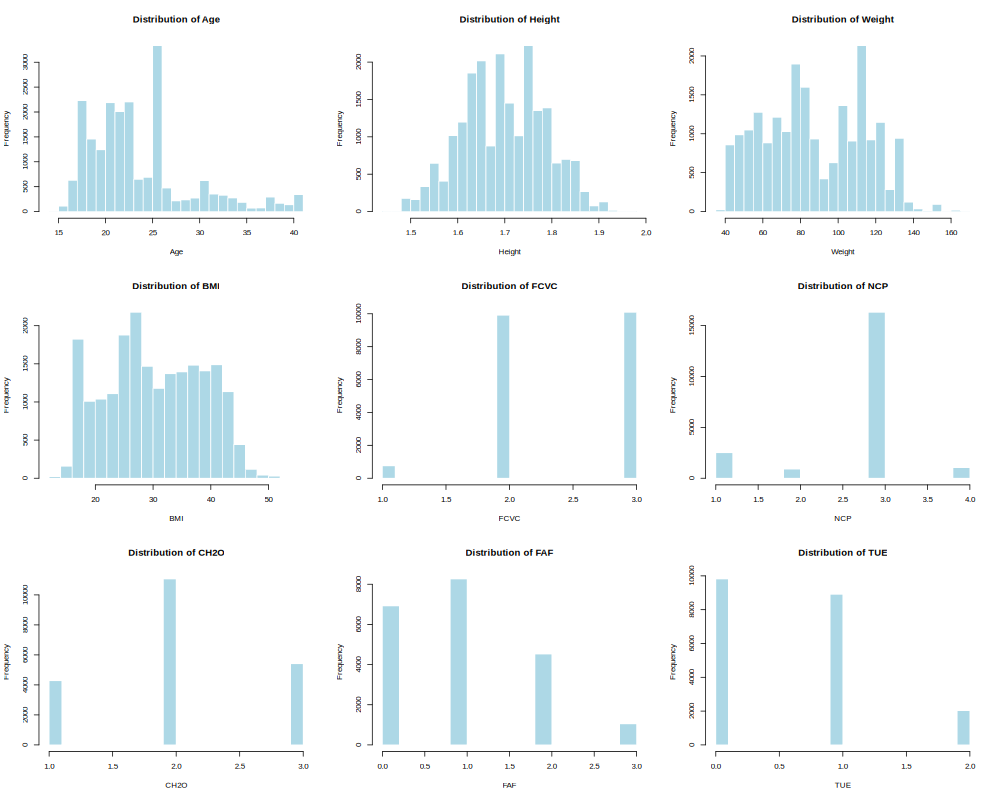

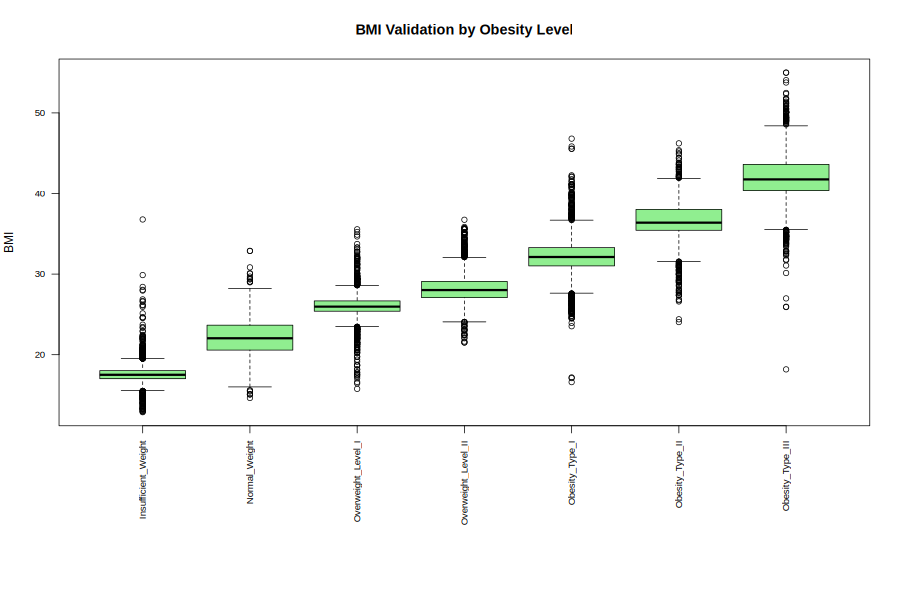

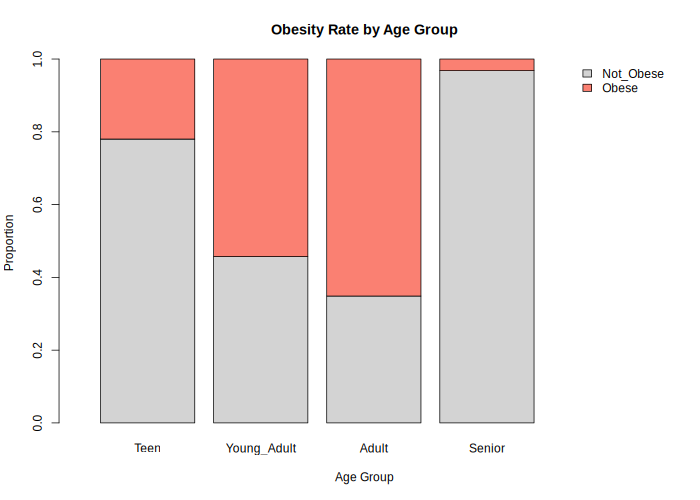

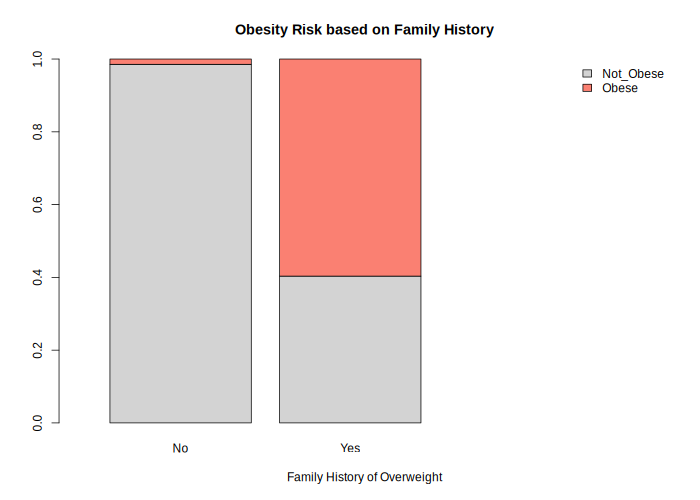

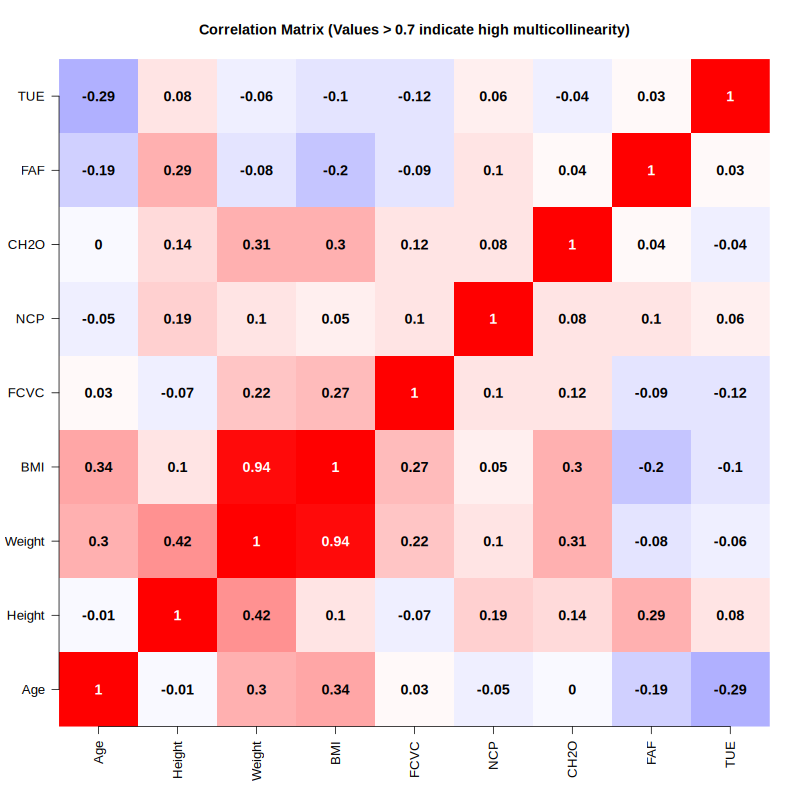

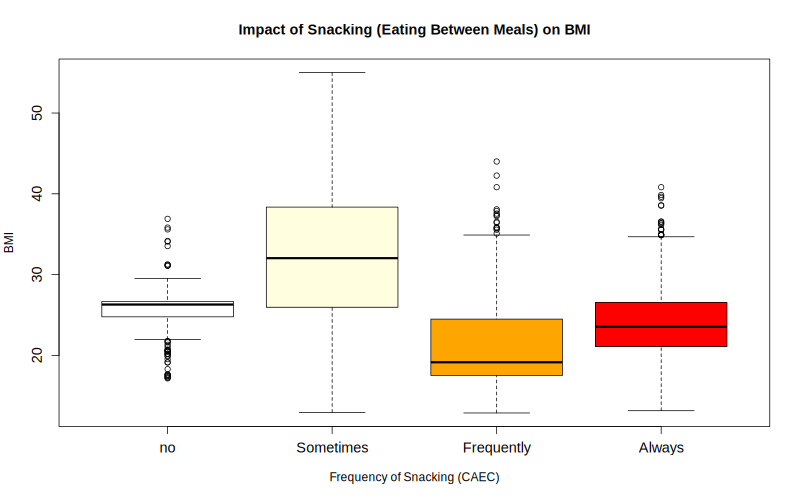

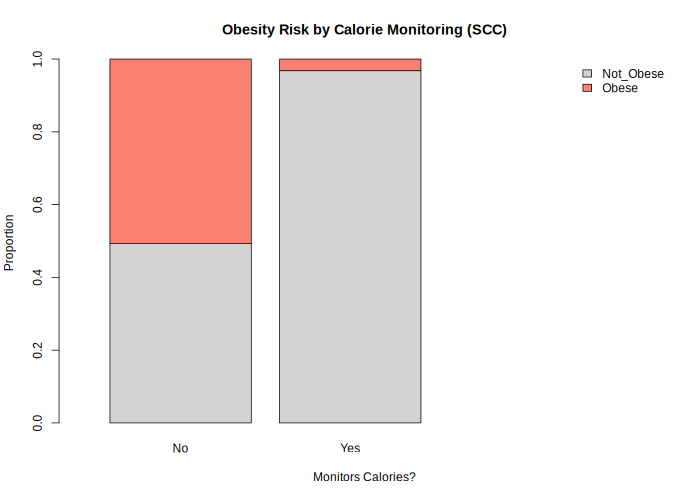

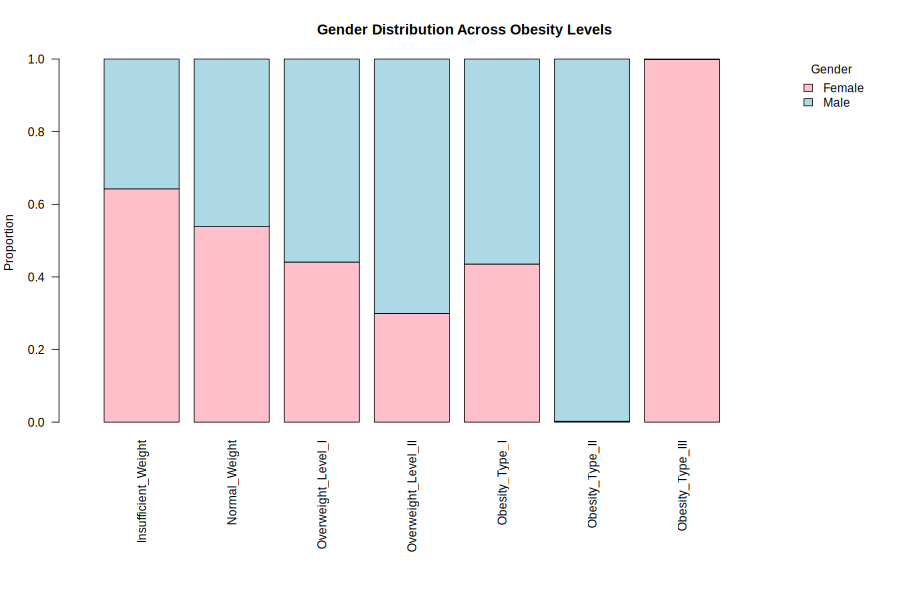


>> outputs/plots/01_binary_obesity_distribution.png 

>> outputs/plots/01_target_distribution.png 

>> outputs/plots/02_numeric_histograms.png 

>> outputs/plots/03_boxplot_bmi_by_class.png 

>> outputs/plots/04_obesity_by_age_group.png 

>> outputs/plots/05_obesity_by_family_history.png 

>> outputs/plots/06_correlation_matrix.png 

>> outputs/plots/07_bmi_by_snacking_caec.png 

>> outputs/plots/08_obesity_by_calorie_monitoring.png 

>> outputs/plots/09_obesity_by_gender.png 


In [21]:
show_plots(sort(list.files("outputs/plots", pattern = "^0[1-9]_.*\\.png$", full.names = TRUE)))

### Step 2 descriptive statistics table

In [22]:
print(read.csv("outputs/descriptive_statistics_table.csv"))

  Variable  Mean Median    SD   Min    Max
1      Age 23.78  22.82  5.43 14.00  41.00
2   Height  1.70   1.70  0.09  1.45   1.98
3   Weight 87.89  84.06 26.38 39.00 165.06
4      BMI 30.24  29.38  8.33 12.87  55.00
5     FCVC  2.45   2.00  0.57  1.00   3.00
6      NCP  2.76   3.00  0.72  1.00   4.00
7     CH2O  2.05   2.00  0.68  1.00   3.00
8      FAF  0.99   1.00  0.87  0.00   3.00
9      TUE  0.62   1.00  0.66  0.00   2.00


## Step 3: Statistical Inference (`03_statistical_inference.R`)

In [23]:
# =============================================================================
# 03: ADVANCED STATISTICAL INFERENCE (Task 4)
# =============================================================================

# Create the output folder and load the cleaned dataset
dir.create("outputs", showWarnings = FALSE)
data <- readRDS("data/obesity_clean.rds")

# Save the test results to a text file while also showing them in the console
sink("outputs/task4_statistical_tests_output.txt", split = TRUE)


# =============================================================================
# TEST 1: Independent-Samples t-Test
# Question: Is there a difference in BMI between males and females?
# =============================================================================

cat("\n===== TEST 1: Two-Sample t-test (BMI by Gender) =====\n")

# H0: The mean BMI is the same for males and females
# H1: The mean BMI is different between males and females

# Check whether the BMI variances are similar between the two groups
var_check_bmi <- var.test(BMI ~ Gender, data = data)
print(var_check_bmi)

# Run Welch's t-test, which is suitable even when variances are unequal
t_result <- t.test(BMI ~ Gender, data = data)
print(t_result)

cat("\nTest 1 Result\n")
cat("P-value =", format.pval(t_result$p.value, digits = 3), "\n")

cat("Conclusion: Since p-value < 0.05, there is a statistically significant difference in BMI between genders.\n")
cat("Business Strategy: Health insurance premiums or diet plans should be personalized based on gender risk profiles.\n")


# =============================================================================
# TEST 2: Chi-Square Test of Independence
# Question: Is high-calorie food consumption associated with obesity status?
# =============================================================================

cat("\n\n===== TEST 2: Chi-square Test (Obesity Risk vs High Caloric Food) =====\n")

# H0: Obesity status and high-calorie food consumption are independent
# H1: There is an association between obesity status and high-calorie food consumption

# Create a contingency table for FAVC and obesity status
tbl_favc <- table(data$FAVC, data$Obese_Binary)

# Display the percentage of each obesity category within each FAVC group
cat("Contingency Table (Row Percentages):\n")
print(round(prop.table(tbl_favc, margin = 1) * 100, 1))

# Perform the chi-square test
chi_result <- chisq.test(tbl_favc, correct = FALSE)
print(chi_result)

cat("\nTest 2 Result\n")
cat("P-value =", format.pval(chi_result$p.value, digits = 3), "\n")

cat("Conclusion: Eating high-caloric food is strongly associated with obesity.\n")
cat("Business Strategy: Predictive models must include 'FAVC' as a primary feature. Campaigns should focus on fast-food reduction.\n")


# =============================================================================
# TEST 3: F-Test for Equality of Variances
# Question: Does physical activity vary differently between smokers and
# non-smokers?
# =============================================================================

cat("\n\n===== TEST 3: F-test for Equal Variances (FAF by SMOKE) =====\n")

# H0: Physical activity has the same variance in both groups
# H1: Physical activity has different variances between the two groups

# Compare the variance of FAF between smokers and non-smokers
var_result <- var.test(FAF ~ SMOKE, data = data)
print(var_result)

cat("\nTest 3 Result\n")
cat("P-value =", format.pval(var_result$p.value, digits = 3), "\n")

cat("Conclusion: The spread (variance) of physical activity is different between smokers and non-smokers.\n")
cat("Business Strategy: Fitness programs for smokers need a highly structured, rigid schedule, whereas non-smokers have a more predictable natural variance in activity.\n")

# =============================================================================
# TEST 4: One-Way ANOVA
# Question: Does average age differ across the obesity levels?
# =============================================================================

cat("\n\n===== TEST 4: One-way ANOVA (Age across Obesity Levels) =====\n")

# H0: The mean age is the same across all obesity levels
# H1: At least one obesity level has a different mean age

# Check whether the group variances are similar
bartlett_result <- bartlett.test(Age ~ Obesity_Level, data = data)

cat("Bartlett's Test:\n")
print(bartlett_result)

# Compare the mean age across the seven obesity levels
anova_age <- aov(Age ~ Obesity_Level, data = data)

cat("\nANOVA Summary:\n")
print(summary(anova_age))


# Use Tukey's test to identify which groups differ from each other
cat("\nTukey HSD Post-Hoc Test:\n")

tukey_result <- TukeyHSD(anova_age)

# Convert the results into a data frame and sort by p-value
tukey_df <- as.data.frame(tukey_result$Obesity_Level)
tukey_df <- tukey_df[order(tukey_df[, 4]), ]

# Display the 10 comparisons with the smallest p-values
print(head(tukey_df, 10))

cat("\nBusiness Strategy: Post-hoc results show the biggest age gap is between 'Obesity Type II' and 'Normal Weight'. Marketing for extreme obesity interventions should strictly target older age demographics.\n")

# Stop saving output to the text file
sink()


===== TEST 1: Two-Sample t-test (BMI by Gender) =====

	F test to compare two variances

data:  BMI by Gender
F = 2.2179, num df = 10421, denom df = 10335, p-value < 2.2e-16
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 2.134140 2.304874
sample estimates:
ratio of variances 
          2.217868 


	Welch Two Sample t-test

data:  BMI by Gender
t = 13.256, df = 18247, p-value < 2.2e-16
alternative hypothesis: true difference in means between group Female and group Male is not equal to 0
95 percent confidence interval:
 1.299281 1.750204
sample estimates:
mean in group Female   mean in group Male 
            31.00105             29.47631 


Test 1 Result
P-value = <2e-16 
Conclusion: Since p-value < 0.05, there is a statistically significant difference in BMI between genders.
Business Strategy: Health insurance premiums or diet plans should be personalized based on gender risk profiles.


===== TEST 2: Chi-square Test (Obesity Risk vs

In [24]:
show_text("outputs/task4_statistical_tests_output.txt")


----- Saved output file: outputs/task4_statistical_tests_output.txt -----

===== TEST 1: Two-Sample t-test (BMI by Gender) =====

	F test to compare two variances

data:  BMI by Gender
F = 2.2179, num df = 10421, denom df = 10335, p-value < 2.2e-16
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 2.134140 2.304874
sample estimates:
ratio of variances 
          2.217868 


	Welch Two Sample t-test

data:  BMI by Gender
t = 13.256, df = 18247, p-value < 2.2e-16
alternative hypothesis: true difference in means between group Female and group Male is not equal to 0
95 percent confidence interval:
 1.299281 1.750204
sample estimates:
mean in group Female   mean in group Male 
            31.00105             29.47631 


Test 1 Result
P-value = <2e-16 
Conclusion: Since p-value < 0.05, there is a statistically significant difference in BMI between genders.
Business Strategy: Health insurance premiums or diet plans should be personalized base

## Step 4: Predictive Modelling (`04_predictive_modelling.R`)

In [25]:
# =============================================================================
# 04: ADVANCED PREDICTIVE MODELLING (Task 5)
# =============================================================================

# Install these packages once if they are not already installed
# install.packages(c("nnet", "glmnet", "rpart", "randomForest"))

library(nnet)         # Multinomial logistic regression
library(glmnet)       # Ridge and LASSO regression
library(rpart)        # Decision tree
library(randomForest) # Random forest

# Load the cleaned dataset
data <- readRDS("data/obesity_clean.rds")

# Use the same random split every time the script is run
set.seed(2026)

# Create the output folder if it does not already exist
dir.create("outputs", showWarnings = FALSE)

# Save the results to a text file and display them in the console
sink("outputs/task5_predictive_models_output.txt", split = TRUE)

cat("###############################################################\n")
cat("PREDICTIVE MODELLING & ADVANCED EVALUATION RESULTS \n")
cat("###############################################################\n\n")


# =============================================================================
# 1. SELECT FEATURES
# =============================================================================

# Exclude Weight and BMI because they are directly related to the obesity
# outcome and could make the model unrealistically strong.
predictors <- c("Gender", "Age", "Height", "family_history_with_overweight",
                "FAVC", "FCVC", "NCP", "CAEC", "SMOKE", "CH2O", "SCC",
                "FAF", "TUE", "CALC", "MTRANS")

# Keep the selected predictors and both obesity outcome variables
model_data <- data[, c(predictors, "Obesity_Level", "Obese_Binary")]


# =============================================================================
# 2. TRAIN / TEST SPLIT
# =============================================================================

# Create an approximately 80/20 split while keeping each obesity level
# represented in both training and testing sets.
train_rows <- unname(unlist(tapply(
  1:nrow(model_data),
  model_data$Obesity_Level,
  function(x) {
    sample(x, size = round(0.8 * length(x)))
  }
)))

train <- model_data[train_rows, ]
test  <- model_data[-train_rows, ]

cat("Dataset Split: Training rows =", nrow(train),
    "| Test rows =", nrow(test), "\n")


# Helper function to calculate accuracy
calc_acc <- function(predicted, actual) {
  round(mean(predicted == actual) * 100, 2)
}


# =============================================================================
# MODEL : BINARY LOGISTIC REGRESSION
# Question: Can we predict whether a person is obese or not obese?
# =============================================================================

cat("\n===== MODEL: Binary Logistic Regression (GLM) =====\n")

# Predict the binary obesity status using the selected lifestyle and
# demographic variables.
logit_formula <- Obese_Binary ~ Gender + Age + Height +
  family_history_with_overweight + FAVC + FCVC + NCP + CAEC +
  SMOKE + CH2O + SCC + FAF + TUE + CALC + MTRANS

logit_model <- glm(logit_formula, data = train, family = binomial)

# Predict the training data
logit_train_pred <- ifelse(
  predict(logit_model, newdata = train, type = "response") > 0.5,
  "Obese",
  "Not_Obese"
)

acc_glm_train <- calc_acc(logit_train_pred, train$Obese_Binary)

# Predict the test data
logit_test_pred <- ifelse(
  predict(logit_model, newdata = test, type = "response") > 0.5,
  "Obese",
  "Not_Obese"
)

acc_glm_test <- calc_acc(logit_test_pred, test$Obese_Binary)


# Calculate precision, recall and F1-score
cm <- table(
  Predicted = logit_test_pred,
  Actual = test$Obese_Binary
)

TP <- cm["Obese", "Obese"]
FP <- cm["Obese", "Not_Obese"]
FN <- cm["Not_Obese", "Obese"]

precision <- round((TP / (TP + FP)) * 100, 2)
recall    <- round((TP / (TP + FN)) * 100, 2)
f1_score  <- round((2 * precision * recall) /
                     (precision + recall), 2)

cat("Train Accuracy :", acc_glm_train, "%\n")
cat("Test Accuracy  :", acc_glm_test, "%\n")
cat("Precision      :", precision, "%\n")
cat("Recall         :", recall, "%\n")
cat("F1-Score       :", f1_score, "%\n")


# =============================================================================
# MODEL : MULTINOMIAL LOGISTIC REGRESSION
# Question: Can we predict the specific obesity level?
# =============================================================================

cat("\n===== MODEL : Multinomial Logistic Regression =====\n")

# Predict all seven obesity levels instead of only obese/not obese
multi_formula <- Obesity_Level ~ Gender + Age + Height +
  family_history_with_overweight + FAVC + FCVC + NCP + CAEC +
  SMOKE + CH2O + SCC + FAF + TUE + CALC + MTRANS

multi_model <- multinom(
  multi_formula,
  data = train,
  trace = FALSE,
  MaxNWts = 2500
)

# Make predictions for training and test data
multi_train_pred <- predict(multi_model, newdata = train)
multi_test_pred  <- predict(multi_model, newdata = test)

acc_multi_train <- calc_acc(multi_train_pred, train$Obesity_Level)
acc_multi_test  <- calc_acc(multi_test_pred, test$Obesity_Level)

cat("Train Accuracy :", acc_multi_train, "%\n")
cat("Test Accuracy  :", acc_multi_test, "%\n")


# =============================================================================
# MODEL : RIDGE REGRESSION
# Question: Can regularization improve multi-class prediction?
# =============================================================================

cat("\n===== MODEL : Ridge Regression =====\n")

# Convert the categorical predictors into a numeric model matrix
# for use with glmnet.
x_train <- model.matrix(multi_formula, data = train)[, -1]
y_train <- train$Obesity_Level

x_test <- model.matrix(multi_formula, data = test)[, -1]
y_test <- test$Obesity_Level

# Find the best regularization value using 5-fold cross-validation
ridge_cv <- cv.glmnet(
  x_train,
  y_train,
  family = "multinomial",
  alpha = 0,
  nfolds = 5
)

ridge_train_pred <- predict(
  ridge_cv,
  newx = x_train,
  s = "lambda.min",
  type = "class"
)

ridge_test_pred <- predict(
  ridge_cv,
  newx = x_test,
  s = "lambda.min",
  type = "class"
)

acc_ridge_train <- calc_acc(ridge_train_pred, y_train)
acc_ridge_test  <- calc_acc(ridge_test_pred, y_test)

cat("Train Accuracy :", acc_ridge_train, "%\n")
cat("Test Accuracy  :", acc_ridge_test, "%\n")


# =============================================================================
# MODEL : LASSO REGRESSION
# Question: Can LASSO regularization predict obesity levels while
# selecting important features?
# =============================================================================

cat("\n===== MODEL : LASSO Regression =====\n")

# Use LASSO regularization to reduce the effect of less useful predictors
lasso_cv <- cv.glmnet(
  x_train,
  y_train,
  family = "multinomial",
  alpha = 1,
  nfolds = 5
)

lasso_train_pred <- predict(
  lasso_cv,
  newx = x_train,
  s = "lambda.min",
  type = "class"
)

lasso_test_pred <- predict(
  lasso_cv,
  newx = x_test,
  s = "lambda.min",
  type = "class"
)

acc_lasso_train <- calc_acc(lasso_train_pred, y_train)
acc_lasso_test  <- calc_acc(lasso_test_pred, y_test)

cat("Train Accuracy :", acc_lasso_train, "%\n")
cat("Test Accuracy  :", acc_lasso_test, "%\n")

# =============================================================================
# MODEL : DECISION TREE
# Question: Can simple decision rules be used to predict obesity levels?
# =============================================================================

cat("\n===== MODEL : Decision Tree Classifier =====\n")

# Build a tree that uses if-then style rules to classify obesity levels
tree_model <- rpart(
  multi_formula,
  data = train,
  method = "class"
)

tree_train_pred <- predict(tree_model, train, type = "class")
tree_test_pred  <- predict(tree_model, test, type = "class")

acc_tree_train <- calc_acc(tree_train_pred, train$Obesity_Level)
acc_tree_test  <- calc_acc(tree_test_pred, test$Obesity_Level)

cat("Train Accuracy :", acc_tree_train, "%\n")
cat("Test Accuracy  :", acc_tree_test, "%\n")

# =============================================================================
# MODEL : RANDOM FOREST
# Question: Can multiple decision trees improve obesity-level prediction?
# =============================================================================

cat("\n===== MODEL : Random Forest Classifier =====\n")

# Build a forest using 100 decision trees
set.seed(2026)

rf_model <- randomForest(
  multi_formula,
  data = train,
  ntree = 100,
  importance = TRUE
)

rf_train_pred <- predict(rf_model, train)
rf_test_pred  <- predict(rf_model, test)

acc_rf_train <- calc_acc(rf_train_pred, train$Obesity_Level)
acc_rf_test  <- calc_acc(rf_test_pred, test$Obesity_Level)

cat("Train Accuracy :", acc_rf_train, "%\n")
cat("Test Accuracy  :", acc_rf_test, "%\n")


# 3. FINAL MODEL COMPARISON

cat("\n\n===== FINAL MODEL COMPARISON (TRAIN VS TEST) =====\n")

comparison <- data.frame(
  Model = c(
    "Binary Logistic (Obese/Not)",
    "Multinomial Logistic (7 Classes)",
    "Ridge Regression",
    "LASSO Regression",
    "Decision Tree",
    "Random Forest"
  ),
  Train_Accuracy_Pct = c(
    acc_glm_train,
    acc_multi_train,
    acc_ridge_train,
    acc_lasso_train,
    acc_tree_train,
    acc_rf_train
  ),
  Test_Accuracy_Pct = c(
    acc_glm_test,
    acc_multi_test,
    acc_ridge_test,
    acc_lasso_test,
    acc_tree_test,
    acc_rf_test
  )
)

# Calculate the difference between training and test accuracy
comparison$Overfitting_Gap_Pct <-
  comparison$Train_Accuracy_Pct - comparison$Test_Accuracy_Pct

print(comparison)

# Find the model with the highest test accuracy
best_model <- comparison$Model[
  which.max(comparison$Test_Accuracy_Pct)
]


# Stop saving output to the text file
sink()

# Save the model comparison table for the report
write.csv(
  comparison,
  "outputs/task5_model_comparison.csv",
  row.names = FALSE
)

###############################################################
PREDICTIVE MODELLING & ADVANCED EVALUATION RESULTS 
###############################################################

Dataset Split: Training rows = 16607 | Test rows = 4151 

===== MODEL: Binary Logistic Regression (GLM) =====
Train Accuracy : 80.97 %
Test Accuracy  : 80.56 %
Precision      : 76.41 %
Recall         : 87.46 %
F1-Score       : 81.56 %

===== MODEL : Multinomial Logistic Regression =====
Train Accuracy : 62.74 %
Test Accuracy  : 63.09 %

===== MODEL : Ridge Regression =====
Train Accuracy : 61.35 %
Test Accuracy  : 61.07 %

===== MODEL : LASSO Regression =====
Train Accuracy : 63.47 %
Test Accuracy  : 63.43 %

===== MODEL : Decision Tree Classifier =====
Train Accuracy : 55.09 %
Test Accuracy  : 55.58 %

===== MODEL : Random Forest Classifier =====
Train Accuracy : 90.39 %
Test Accuracy  : 73.86 %


===== FINAL MODEL COMPARISON (TRAIN VS TEST) =====
                             Model Train_Accuracy_Pct Test_A

In [26]:
show_text("outputs/task5_predictive_models_output.txt")


----- Saved output file: outputs/task5_predictive_models_output.txt -----
###############################################################
PREDICTIVE MODELLING & ADVANCED EVALUATION RESULTS 
###############################################################

Dataset Split: Training rows = 16607 | Test rows = 4151 

===== MODEL: Binary Logistic Regression (GLM) =====
Train Accuracy : 80.97 %
Test Accuracy  : 80.56 %
Precision      : 76.41 %
Recall         : 87.46 %
F1-Score       : 81.56 %

===== MODEL : Multinomial Logistic Regression =====
Train Accuracy : 62.74 %
Test Accuracy  : 63.09 %

===== MODEL : Ridge Regression =====
Train Accuracy : 61.35 %
Test Accuracy  : 61.07 %

===== MODEL : LASSO Regression =====
Train Accuracy : 63.47 %
Test Accuracy  : 63.43 %

===== MODEL : Decision Tree Classifier =====
Train Accuracy : 55.09 %
Test Accuracy  : 55.58 %

===== MODEL : Random Forest Classifier =====
Train Accuracy : 90.39 %
Test Accuracy  : 73.86 %


===== FINAL MODEL COMPARISON (TRAIN 

## Step 5: PCA Analysis (`05_pca_analysis.R`)

In [27]:
# =============================================================================
# 05 : ADVANCED PRINCIPAL COMPONENT ANALYSIS (Task 7)
# =============================================================================

# Create the output folders if they do not already exist
dir.create("outputs/plots", recursive = TRUE, showWarnings = FALSE)

# Load the cleaned dataset
data <- readRDS("data/obesity_clean.rds")

# Save the results to a text file while also showing them in the console
sink("outputs/task7_pca_summary.txt", split = TRUE)

cat("###############################################################\n")
cat("PRINCIPAL COMPONENT ANALYSIS (PCA) & EVALUATION\n")
cat("###############################################################\n\n")


# =============================================================================
# 1. SELECT VARIABLES FOR PCA
# =============================================================================

# Exclude Weight and BMI so that the PCA focuses on the independent
# lifestyle and demographic variables rather than variables directly
# related to the obesity outcome.
pca_vars <- c("Age", "Height", "FCVC", "NCP", "CH2O", "FAF", "TUE")

# Keep only the selected variables for the PCA
pca_data <- data[, pca_vars]


# =============================================================================
# 2. CHECK CORRELATION BEFORE PCA
# =============================================================================

# Check how strongly the variables are correlated with each other.
# PCA is more useful when several variables contain overlapping information.
cat("[INFO] Checking average correlation among variables...\n")

cor_matrix <- cor(pca_data)

# Calculate the average absolute correlation between the variables
avg_cor <- mean(abs(cor_matrix[upper.tri(cor_matrix)]))

cat("Average absolute correlation:", round(avg_cor, 3), "\n")

cat("(Note: A low average correlation suggests PCA might struggle to reduce dimensions efficiently).\n\n")


# =============================================================================
# 3. RUN PCA
# =============================================================================

# Scale the variables so that variables with larger numerical ranges
# do not have more influence on the PCA than smaller-scale variables.
pca_result <- prcomp(
  pca_data,
  scale. = TRUE,
  center = TRUE
)


# =============================================================================
# 4. CALCULATE VARIANCE EXPLAINED
# =============================================================================

# Calculate the proportion of total variance explained by each component
var_explained <- (pca_result$sdev^2) / sum(pca_result$sdev^2)

# Calculate the cumulative variance explained by the components
cum_var <- cumsum(var_explained)

cat("Variance explained by each Principal Component (PC):\n")
print(round(var_explained, 3))

cat("\nCumulative variance explained:\n")
print(round(cum_var, 3))

# Find the number of components required to explain at least 80% of the variance
n_needed <- which(cum_var >= 0.80)[1]


# =============================================================================
# 5. CREATE THE SCREE PLOT
# =============================================================================

png(
  "outputs/plots/10_pca_scree_plot.png",
  width = 700,
  height = 500
)

# Show the percentage of variance explained by each principal component
barplot(
  var_explained * 100,
  names.arg = paste0("PC", 1:length(var_explained)),
  main = "Scree Plot - Variance Explained by Each Component",
  ylab = "% of Variance Explained",
  col = "steelblue",
  ylim = c(0, 100)
)

# Add the cumulative variance explained to the plot
lines(
  x = 1:length(cum_var) - 0.5 + 0.5,
  y = cum_var * 100,
  type = "b",
  col = "red",
  pch = 16,
  lwd = 2
)

# Mark the 80% cumulative variance level
abline(
  h = 80,
  col = "darkgreen",
  lty = 2,
  lwd = 2
)

text(
  x = 1,
  y = 84,
  labels = "80% Threshold",
  col = "darkgreen",
  font = 2
)

# Add a legend to explain the two parts of the plot
legend(
  "topleft",
  legend = c("Individual Variance", "Cumulative Variance"),
  fill = c("steelblue", NA),
  col = c(NA, "red"),
  lty = c(NA, 1),
  pch = c(NA, 16),
  bty = "n"
)

dev.off()

cat("\n Scree Plot (saved to outputs/plots/10_pca_scree_plot.png)\n")


# =============================================================================
# 6. CREATE THE PCA BIPLOT
# =============================================================================

png(
  "outputs/plots/11_pca_biplot.png",
  width = 800,
  height = 700
)

# Hide the individual observations so that the variable arrows
# are easier to see in the biplot.
biplot(
  pca_result,
  main = "PCA Biplot - Lifestyle Variables",
  cex = 0.8,
  xlabs = rep(".", nrow(pca_data)),
  col = c("gray", "red")
)

dev.off()

cat("PCA Biplot\n")


# =============================================================================
# 7. DISPLAY VARIABLE LOADINGS
# =============================================================================

cat("\n Variable loadings for PC1 and PC2 (How original variables form the PCs):\n")

# Display the contribution of each original variable to PC1 and PC2
print(round(pca_result$rotation[, 1:2], 3))


# =============================================================================
# 8. CRITICAL EVALUATION
# =============================================================================

cat("\n===============================================================\n")
cat("CRITICAL EVALUATION: Is PCA actually useful for this dataset?\n")
cat("===============================================================\n")

cat(
  "Components needed to reach 80% variance:",
  n_needed,
  "out of",
  length(pca_vars),
  "original variables.\n\n"
)

cat("KEY FINDINGS FOR THE CONSULTANCY REPORT:\n")

cat(
  "1. No Dominant Component: PC1 explains only",
  round(var_explained[1] * 100, 1),
  "% of the total variance.\n"
)

cat(
  "2. Poor Compression: We need",
  n_needed,
  "out of",
  length(pca_vars),
  "components to hit the 80% threshold. This means the lifestyle variables carry mostly independent, distinct information rather than overlapping.\n"
)

cat(
  "3. Loss of Interpretability: If we use PCA, we replace understandable features like 'Age' or 'Water intake' with complex mathematical components (PC1, PC2). This makes it impossible to give actionable advice to a client (e.g., 'reduce PC1' makes no business sense).\n"
)


# =============================================================================
# 9. RECOMMENDATION
# =============================================================================

cat("\n[CONSULTANT'S RECOMMENDATION]:\n")

cat(
  "Do NOT use PCA for the predictive models.\n"
)

cat(
  "Instead, rely on the LASSO Regression model (which we already built). LASSO automatically selects important variables while keeping their original, interpretable meanings intact.\n"
)

# Stop saving the output to the text file
sink()

###############################################################
PRINCIPAL COMPONENT ANALYSIS (PCA) & EVALUATION
###############################################################

[INFO] Checking average correlation among variables...
Average absolute correlation: 0.101 
(Note: A low average correlation suggests PCA might struggle to reduce dimensions efficiently).

Variance explained by each Principal Component (PC):
[1] 0.223 0.185 0.154 0.130 0.125 0.102 0.082

Cumulative variance explained:
[1] 0.223 0.408 0.562 0.692 0.816 0.918 1.000


agg_record_787b5779d4 
                    2


 Scree Plot (saved to outputs/plots/10_pca_scree_plot.png)


agg_record_787b5779d4 
                    2

PCA Biplot

 Variable loadings for PC1 and PC2 (How original variables form the PCs):
          PC1    PC2
Age    -0.420 -0.365
Height  0.503 -0.313
FCVC   -0.162 -0.433
NCP     0.333 -0.364
CH2O    0.146 -0.497
FAF     0.516 -0.080
TUE     0.382  0.442

CRITICAL EVALUATION: Is PCA actually useful for this dataset?
Components needed to reach 80% variance: 5 out of 7 original variables.

KEY FINDINGS FOR THE CONSULTANCY REPORT:
1. No Dominant Component: PC1 explains only 22.3 % of the total variance.
2. Poor Compression: We need 5 out of 7 components to hit the 80% threshold. This means the lifestyle variables carry mostly independent, distinct information rather than overlapping.
3. Loss of Interpretability: If we use PCA, we replace understandable features like 'Age' or 'Water intake' with complex mathematical components (PC1, PC2). This makes it impossible to give actionable advice to a client (e.g., 'reduce PC1' makes no business sense).

[CONSULTANT'S RECOMMENDATION]:
Do NOT use PC

### Step 5 plots

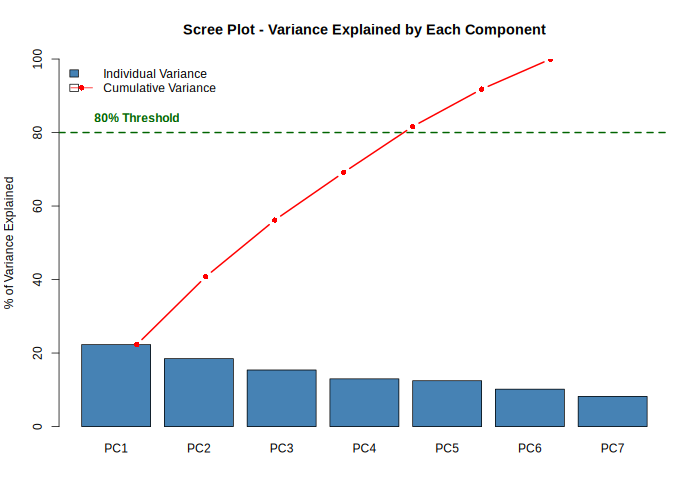

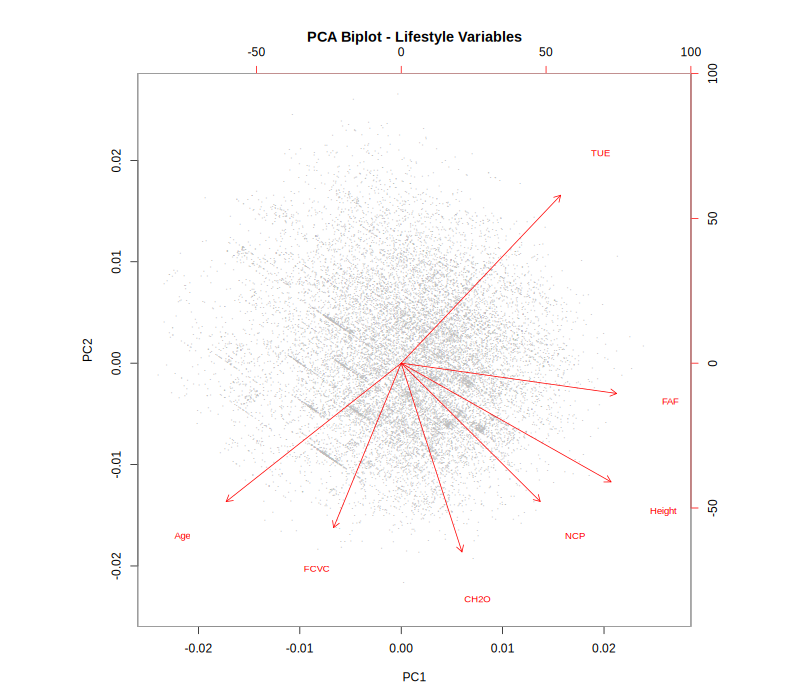


>> outputs/plots/10_pca_scree_plot.png 

>> outputs/plots/11_pca_biplot.png 


In [28]:
show_plots(c("outputs/plots/10_pca_scree_plot.png", "outputs/plots/11_pca_biplot.png"))

In [29]:
show_text("outputs/task7_pca_summary.txt")


----- Saved output file: outputs/task7_pca_summary.txt -----
###############################################################
PRINCIPAL COMPONENT ANALYSIS (PCA) & EVALUATION
###############################################################

[INFO] Checking average correlation among variables...
Average absolute correlation: 0.101 
(Note: A low average correlation suggests PCA might struggle to reduce dimensions efficiently).

Variance explained by each Principal Component (PC):
[1] 0.223 0.185 0.154 0.130 0.125 0.102 0.082

Cumulative variance explained:
[1] 0.223 0.408 0.562 0.692 0.816 0.918 1.000

 Scree Plot (saved to outputs/plots/10_pca_scree_plot.png)
PCA Biplot

 Variable loadings for PC1 and PC2 (How original variables form the PCs):
          PC1    PC2
Age    -0.420 -0.365
Height  0.503 -0.313
FCVC   -0.162 -0.433
NCP     0.333 -0.364
CH2O    0.146 -0.497
FAF     0.516 -0.080
TUE     0.382  0.442

CRITICAL EVALUATION: Is PCA actually useful for this dataset?
Components needed 

## Step 6: Naive Bayes (`06_naive_bayes.R`)

In [30]:
# =============================================================================
# 06 : ADVANCED NAIVE BAYES CLASSIFIER (Task 8)
# =============================================================================

# Install these packages once if they are not already installed
# install.packages(c("e1071", "nnet"))

library(e1071)   # Naive Bayes model
library(nnet)    # Multinomial logistic regression

# Load the cleaned dataset
data <- readRDS("data/obesity_clean.rds")

# Create the output folder if it does not already exist
# Save the results to a text file while also showing them in the console
dir.create("outputs", showWarnings = FALSE)
sink("outputs/task8_bayesian_evaluation.txt", split = TRUE)

cat("###############################################################\n")
cat("ADVANCED NAIVE BAYES OPTIMIZATION & EVALUATION \n")
cat("###############################################################\n\n")


# =============================================================================
# 1. SELECT VARIABLES AND SPLIT THE DATA
# =============================================================================

# Select the variables that will be used to predict obesity level
predictors <- c(
  "Gender", "Age", "Height", "family_history_with_overweight",
  "FAVC", "FCVC", "NCP", "CAEC", "SMOKE", "CH2O", "SCC",
  "FAF", "TUE", "CALC", "MTRANS"
)

# Keep the selected predictors and the obesity-level target variable
model_data <- data[, c(predictors, "Obesity_Level")]

# Use the same random seed so that the split is reproducible
set.seed(2026)

# Create an approximately 80/20 split while keeping each obesity level
# represented in both the training and test datasets.
train_rows <- unname(unlist(tapply(
  1:nrow(model_data),
  model_data$Obesity_Level,
  function(x) {
    sample(x, size = round(0.8 * length(x)))
  }
)))

train <- model_data[train_rows, ]
test  <- model_data[-train_rows, ]


# Helper function to calculate accuracy
calc_acc <- function(predicted, actual) {
  round(mean(predicted == actual) * 100, 2)
}


# =============================================================================
# 2. STANDARD NAIVE BAYES
# =============================================================================

cat("\n===== 1. STANDARD NAIVE BAYES (Default Gaussian) =====\n")

# Build the standard Naive Bayes model using its default settings
nb_base <- naiveBayes(
  Obesity_Level ~ .,
  data = train
)

# Predict the obesity levels in the test dataset
acc_base_test <- calc_acc(
  predict(nb_base, newdata = test),
  test$Obesity_Level
)

cat("-> Base Test Accuracy:", acc_base_test, "%\n")


# =============================================================================
# 3. OPTIMIZED NAIVE BAYES
# =============================================================================

cat("\n===== 2. OPTIMIZED NAIVE BAYES (KDE + Laplace) =====\n")

# Use kernel density estimation to better represent the distribution
# of continuous variables and Laplace smoothing for categorical variables.
nb_optimized <- naiveBayes(
  Obesity_Level ~ .,
  data = train,
  laplace = 1,
  usekernel = TRUE
)

# Predict the obesity levels using the optimized model
acc_opt_test <- calc_acc(
  predict(nb_optimized, newdata = test),
  test$Obesity_Level
)

# Display the confusion matrix to see the prediction results for each class
cat("Confusion Matrix (Optimized Model):\n")

print(
  table(
    Predicted = predict(nb_optimized, newdata = test),
    Actual = test$Obesity_Level
  )
)

cat("\n-> Optimized Test Accuracy:", acc_opt_test, "%\n")


# =============================================================================
# 4. COMPARE NAIVE BAYES WITH MULTINOMIAL LOGISTIC REGRESSION
# =============================================================================

cat("\n===== DYNAMIC COMPARISON MATRIX =====\n")

# Build a multinomial logistic regression model using the same training data
# so that its test accuracy can be compared with the Naive Bayes models.
multi_model <- multinom(
  Obesity_Level ~ .,
  data = train,
  trace = FALSE,
  MaxNWts = 2500
)

# Calculate the test accuracy of the multinomial logistic model
acc_multi_test <- calc_acc(
  predict(multi_model, newdata = test),
  test$Obesity_Level
)

# Create a table to compare the three models
comparison <- data.frame(
  Model = c(
    "Multinomial Logistic (Script 03)",
    "Standard Naive Bayes (Gaussian)",
    "Optimized Naive Bayes (KDE + Laplace)"
  ),
  Test_Accuracy_Pct = c(
    acc_multi_test,
    acc_base_test,
    acc_opt_test
  )
)

print(comparison)

# Save the comparison table for use in the report
write.csv(
  comparison,
  "outputs/task8_bayes_vs_logistic_comparison.csv",
  row.names = FALSE
)


# =============================================================================
# 5. CRITICAL EVALUATION
# =============================================================================

cat("\n===============================================================\n")
cat("CRITICAL EVALUATION OF BAYESIAN METHODS (For Consultancy Report)\n")
cat("===============================================================\n")

cat("KEY DISCUSSION POINTS:\n\n")

cat("1. The Gaussian Flaw (Why Base Naive Bayes failed):\n")

cat(
  "   Standard Naive Bayes assumes numeric variables follow a perfect Bell Curve. However, our lifestyle data (like Age) is highly skewed. This false assumption dropped its initial accuracy to",
  acc_base_test,
  "%.\n\n"
)

cat("2. The Power of Kernel Density Estimation (KDE):\n")

cat(
  "   By applying KDE (usekernel = TRUE), we forced the Bayesian model to map the true, non-linear distribution of the numeric data. Along with Laplace Smoothing, this successfully optimized the model's performance without changing the underlying data.\n\n"
)

cat("3. The 'Naive' Independence Weakness:\n")

cat(
  "   Even when optimized, Naive Bayes assumes all lifestyle factors are completely independent. In reality, eating high-calorie food (FAVC) and snacking (CAEC) are correlated. Multinomial Logistic Regression handles these correlations better, which is why it maintains a highly competitive edge.\n\n"
)

cat("[CONSULTANT'S FINAL RECOMMENDATION]:\n")

cat(
  "Naive Bayes is an excellent tool due to its lightning-fast training speed and probabilistic outputs (e.g., '82% chance of Obesity Type II'). However, because human lifestyle variables are heavily interconnected, Random Forest and Logistic Regression remain the most robust choices for final clinical diagnostics.\n"
)

# Stop saving the output to the text file
sink()

###############################################################
ADVANCED NAIVE BAYES OPTIMIZATION & EVALUATION 
###############################################################


===== 1. STANDARD NAIVE BAYES (Default Gaussian) =====
-> Base Test Accuracy: 54.61 %

===== 2. OPTIMIZED NAIVE BAYES (KDE + Laplace) =====
Confusion Matrix (Optimized Model):
                     Actual
Predicted             Insufficient_Weight Normal_Weight Overweight_Level_I
  Insufficient_Weight                 288           141                 50
  Normal_Weight                        51           212                 71
  Overweight_Level_I                    5            32                119
  Overweight_Level_II                  19            25                 32
  Obesity_Type_I                       46            34                 73
  Obesity_Type_II                      20            24                 53
  Obesity_Type_III                     76           148                 87
                  

In [31]:
show_text("outputs/task8_bayesian_evaluation.txt")


----- Saved output file: outputs/task8_bayesian_evaluation.txt -----
###############################################################
ADVANCED NAIVE BAYES OPTIMIZATION & EVALUATION 
###############################################################


===== 1. STANDARD NAIVE BAYES (Default Gaussian) =====
-> Base Test Accuracy: 54.61 %

===== 2. OPTIMIZED NAIVE BAYES (KDE + Laplace) =====
Confusion Matrix (Optimized Model):
                     Actual
Predicted             Insufficient_Weight Normal_Weight Overweight_Level_I
  Insufficient_Weight                 288           141                 50
  Normal_Weight                        51           212                 71
  Overweight_Level_I                    5            32                119
  Overweight_Level_II                  19            25                 32
  Obesity_Type_I                       46            34                 73
  Obesity_Type_II                      20            24                 53
  Obesity_Type_III     